**ASSIGNMENT - 3 (Comparison)**

# LSTM vs LSTM + Attention: Sentiment Analysis on the US Airline Tweets Dataset (10-Fold Cross Validation)

This notebook compares the two Experiment 3 models:

| Model | Source notebook | Architecture |
|---|---|---|
| **LSTM** | `exp3/lstm_usairlinetweets.ipynb` | Embedding → SpatialDropout1D → BiLSTM(64) → Dropout(0.7) → Dense(3) |
| **LSTM + Attention** | `exp3/lstm_attention_usairlinetweets.ipynb` | Embedding → SpatialDropout1D → BiLSTM(64, return_sequences) → AttentionPooling(64) → Dropout(0.5) → Dense(3) |

Both models use **the same text cleaning, tokenizer, vocabulary size, sequence length, optimizer and callbacks**.
The only difference is the attention layer, so any gap in performance comes from attention.

Instead of a single 60:20:20 split, every model is evaluated with **stratified 10-fold cross validation**:

* The data is split into 10 stratified folds. Each fold is the **test set** exactly once.
* The other 9 folds are the training data. 10% of them is held out as a **validation set** for EarlyStopping / ReduceLROnPlateau.
* The tokenizer is fit **only on the training part of each fold**, so no test words leak into the vocabulary.
* Both models see **exactly the same folds and the same random seed** for each fold, so the 10 scores are paired.

The 10 test-fold scores per model are then compared with **box plots**, a fold-by-fold plot, paired statistical tests and pooled confusion matrices.

In [1]:
%pip install -q tensorflow numpy pandas matplotlib scikit-learn scipy kagglehub


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: /home/rito/ju_lab/ks_lab/exp3/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## Hyperparameters

In [2]:
# Text preprocessing (same as exp3)
vocab_size = 10000
max_length = 40
embedding_dim = 128

# Training (same as exp3)
epochs = 50
batch_size = 10
es_patience = 4        # EarlyStopping patience (val_loss)
lr_patience = 2        # ReduceLROnPlateau patience
lr_factor = 0.5

# Cross validation
n_folds = 10
inner_val_size = 0.10  # part of the 9 training folds used as validation set
seed = 42

# Results are cached in this folder, so plots can be redrawn without retraining.
# Set RERUN = True to train all 2 x 10 models again.
output_dir = "output"
RERUN = False

## Imports

In [3]:
import os
import re
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Embedding, SpatialDropout1D, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    log_loss, confusion_matrix, classification_report
)
from scipy import stats

os.makedirs(output_dir, exist_ok=True)
tf.keras.utils.set_random_seed(seed)
print("TensorFlow:", tf.__version__)

I0000 00:00:1794951759.434168  116023 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1794951765.932355  116023 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.21.0


## Load Dataset

In [4]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
file_path = "Tweets.csv"
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "crowdflower/twitter-airline-sentiment",
  file_path,
)
df = df[['text', 'airline_sentiment']].dropna()
df = df.drop_duplicates(subset='text')   # duplicate tweets could leak between train and test
df = df.reset_index(drop=True)
print(df.shape)
print(df['airline_sentiment'].value_counts())

/home/rito/ju_lab/ks_lab/exp3/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(14427, 2)
airline_sentiment
negative    9080
neutral     3057
positive    2290
Name: count, dtype: int64


## Text Cleaning (same as exp3)

In [5]:
def clean_text(t):
    t = t.lower()
    t = re.sub(r"@\w+", " ", t)
    t = re.sub(r"http\S+|www\S+", " ", t)
    t = re.sub(r"n't", " not", t)                  # keep negation: didn't -> did not
    t = re.sub(r"'(s|re|ve|ll|d|m)\b", " ", t)
    t = re.sub(r"([!?])", r" \1 ", t)              # keep ! and ? as separate tokens
    t = re.sub(r"[^a-z!?\s]", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

df['clean_text'] = df['text'].apply(clean_text)

labels = pd.get_dummies(df['airline_sentiment']).astype(int)
class_names = list(labels.columns)
y = labels.values
y_int = y.argmax(axis=1)
X_text = df['clean_text'].values

print(class_names)
print(df[['text', 'clean_text']].head())

['negative', 'neutral', 'positive']
                                                text  \
0                @VirginAmerica What @dhepburn said.   
1  @VirginAmerica plus you've added commercials t...   
2  @VirginAmerica I didn't today... Must mean I n...   
3  @VirginAmerica it's really aggressive to blast...   
4  @VirginAmerica and it's a really big bad thing...   

                                          clean_text  
0                                          what said  
1  plus you added commercials to the experience t...  
2  i did not today must mean i need to take anoth...  
3  it really aggressive to blast obnoxious entert...  
4             and it a really big bad thing about it  


## Models

Both builders are copied from the exp3 notebooks. Only the part between the BiLSTM and the output layer is different.

In [6]:
def build_lstm():
    model = Sequential([
        Input(shape=(max_length,)),
        Embedding(input_dim=vocab_size, output_dim=embedding_dim, mask_zero=True),  # mask the padding zeros
        SpatialDropout1D(0.3),
        Bidirectional(LSTM(64)),
        Dropout(0.7),
        Dense(3, activation='softmax')
    ], name="LSTM")
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model


class AttentionPooling(layers.Layer):
    # Additive (Bahdanau-style) attention that collapses the time axis and respects the padding mask.
    def __init__(self, units=64, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.supports_masking = True
        self.score_dense = Dense(units, activation='tanh')
        self.score_out = Dense(1, use_bias=False)

    def attention_weights(self, inputs, mask=None):
        scores = self.score_out(self.score_dense(inputs))           # (batch, time, 1)
        if mask is not None:
            mask = tf.cast(mask, scores.dtype)[..., tf.newaxis]
            scores += (1.0 - mask) * -1e9                            # padding tokens get ~0 weight
        return tf.nn.softmax(scores, axis=1)                         # weights over time sum to 1

    def call(self, inputs, mask=None):
        weights = self.attention_weights(inputs, mask)
        return tf.reduce_sum(weights * inputs, axis=1)               # (batch, features)

    def compute_mask(self, inputs, mask=None):
        return None  # time axis is gone, so no mask downstream

    def get_config(self):
        return {**super().get_config(), "units": self.units}


def build_lstm_attention():
    inputs = Input(shape=(max_length,))
    x = Embedding(input_dim=vocab_size, output_dim=embedding_dim, mask_zero=True)(inputs)
    x = SpatialDropout1D(0.3)(x)
    x = Bidirectional(LSTM(64, return_sequences=True), name='bilstm')(x)  # keep every timestep for attention
    x = AttentionPooling(64, name='attention')(x)
    x = Dropout(0.5)(x)
    outputs = Dense(3, activation='softmax')(x)
    model = Model(inputs, outputs, name="LSTM_Attention")
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model


MODELS = {
    "LSTM": build_lstm,
    "LSTM + Attention": build_lstm_attention,
}
MODEL_COLORS = {"LSTM": "#2a78d6", "LSTM + Attention": "#eb6834"}   # fixed colour per model in every plot
MODEL_FILES = {"LSTM": "lstm", "LSTM + Attention": "lstm_attention"}

for name, build in MODELS.items():
    m = build()
    m.summary()
    print(f"{name}: {m.count_params():,} parameters\n")

E0000 00:00:1794951773.461215  116023 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 40, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 40, 128)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,379,203 (5.26 MB)

 Trainable params: 1,379,203 (5.26 MB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 1,387,523 (5.29 MB)

 Trainable params: 1,387,523 (5.29 MB)

 Non-trainable params: 0 (0.00 B)

LSTM + Attention: 1,387,523 parameters



## 10-Fold Cross Validation

For every fold, both models are trained on the same data with the same seed.
For each test fold we record accuracy, macro / weighted F1, macro precision, macro recall, per-class F1, test loss, epochs trained and training time.
The out-of-fold predicted probabilities are saved too, so a pooled confusion matrix can be drawn over the whole dataset.

In [7]:
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
folds = list(skf.split(X_text, y_int))   # the same folds are used for both models


def run_fold(build_fn, fold, train_idx, test_idx):
    # inner train / validation split for EarlyStopping (taken from the 9 training folds only)
    tr_idx, val_idx = train_test_split(
        train_idx, test_size=inner_val_size, random_state=seed + fold, stratify=y_int[train_idx]
    )

    # tokenizer fit on the training part of this fold only
    tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>", filters='')
    tokenizer.fit_on_texts(X_text[tr_idx])

    def encode(texts):
        seq = tokenizer.texts_to_sequences(texts)
        return pad_sequences(seq, maxlen=max_length, padding='post', truncating='post')

    X_tr, X_val, X_te = encode(X_text[tr_idx]), encode(X_text[val_idx]), encode(X_text[test_idx])

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed + fold)    # same seed for both models in this fold
    model = build_fn()

    early_stop = EarlyStopping(monitor='val_loss', patience=es_patience, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=lr_factor, patience=lr_patience)

    start = time.time()
    history = model.fit(
        X_tr, y[tr_idx],
        epochs=epochs,
        batch_size=batch_size,
        validation_data=(X_val, y[val_idx]),
        callbacks=[early_stop, reduce_lr],
        verbose=0
    )
    train_time = time.time() - start

    prob = model.predict(X_te, verbose=0)
    pred = prob.argmax(axis=1)
    true = y_int[test_idx]
    per_class_f1 = f1_score(true, pred, average=None, labels=[0, 1, 2])

    row = {
        "fold": fold + 1,
        "accuracy": accuracy_score(true, pred),
        "f1_macro": f1_score(true, pred, average='macro'),
        "f1_weighted": f1_score(true, pred, average='weighted'),
        "precision_macro": precision_score(true, pred, average='macro', zero_division=0),
        "recall_macro": recall_score(true, pred, average='macro'),
        "test_loss": log_loss(true, prob, labels=[0, 1, 2]),
        "epochs_trained": len(history.history['loss']),
        "best_epoch": int(np.argmin(history.history['val_loss'])) + 1,
        "train_time_s": train_time,
        "n_params": model.count_params(),
    }
    for c, f1 in zip(class_names, per_class_f1):
        row[f"f1_{c}"] = f1
    hist = {k: [float(v) for v in vals] for k, vals in history.history.items()}
    return row, prob, hist


def run_cv(name):
    tag = MODEL_FILES[name]
    csv_path = os.path.join(output_dir, f"cv_results_{tag}.csv")
    oof_path = os.path.join(output_dir, f"oof_probs_{tag}.npy")
    hist_path = os.path.join(output_dir, f"cv_history_{tag}.json")

    if not RERUN and all(os.path.exists(p) for p in (csv_path, oof_path, hist_path)):
        print(f"{name}: loading cached results from {output_dir}/")
        with open(hist_path) as f:
            return pd.read_csv(csv_path), np.load(oof_path), json.load(f)

    rows, histories = [], []
    oof = np.zeros((len(y_int), 3), dtype="float32")
    for fold, (train_idx, test_idx) in enumerate(folds):
        row, prob, hist = run_fold(MODELS[name], fold, train_idx, test_idx)
        oof[test_idx] = prob
        rows.append(row)
        histories.append(hist)
        print(f"{name} | fold {fold + 1:2d}/{n_folds} | acc {row['accuracy']:.4f} | "
              f"macro F1 {row['f1_macro']:.4f} | epochs {row['epochs_trained']:2d} | {row['train_time_s']:.0f}s")

    res = pd.DataFrame(rows)
    res.to_csv(csv_path, index=False)
    np.save(oof_path, oof)
    with open(hist_path, "w") as f:
        json.dump(histories, f)
    return res, oof, histories

In [8]:
results, oof_probs, histories = {}, {}, {}
for name in MODELS:
    results[name], oof_probs[name], histories[name] = run_cv(name)
    print()

LSTM: loading cached results from output/

LSTM + Attention: loading cached results from output/



## Results per Fold

In [9]:
metric_cols = ["accuracy", "f1_macro", "f1_weighted", "precision_macro", "recall_macro",
               "f1_negative", "f1_neutral", "f1_positive", "test_loss", "epochs_trained", "train_time_s"]

per_fold = pd.concat(
    {name: res.set_index("fold")[metric_cols] for name, res in results.items()}, axis=1
)
per_fold.round(4)

LSTM                                                                \
     accuracy f1_macro f1_weighted precision_macro recall_macro f1_negative   
fold                                                                          
1      0.8080   0.7331      0.7984          0.7694       0.7101      0.8867   
2      0.7983   0.7193      0.7863          0.7678       0.6920      0.8763   
3      0.8018   0.7362      0.7934          0.7709       0.7126      0.8749   
4      0.7866   0.7222      0.7812          0.7504       0.7013      0.8626   
5      0.8184   0.7579      0.8129          0.7766       0.7443      0.8900   
6      0.8378   0.7831      0.8334          0.8067       0.7646      0.9013   
7      0.8025   0.7343      0.7967          0.7576       0.7166      0.8798   
8      0.8114   0.7472      0.8090          0.7673       0.7332      0.8883   
9      0.7767   0.6924      0.7681          0.7118       0.6815      0.8695   
10     0.8024   0.7221      0.7868          0.7898       0.6907      0.8766   

                                                      ... LSTM + Attention  \
     f1_neutral f1_positive test_loss epochs_trained  ...         f1_macro   
fold                                                  ...                    
1        0.6026      0.7100    0.5182              5  ...           0.7485   
2        0.5898      0.6918    0.5205              5  ...           0.7060   
3        0.5856      0.7482    0.4946              5  ...           0.7559   
4        0.5907      0.7133    0.5285              5  ...           0.7080   
5        0.6248      0.7589    0.4465              5  ...           0.7572   
6        0.6831      0.7650    0.4444              5  ...           0.7800   
7        0.6208      0.7023    0.5060              5  ...           0.7466   
8        0.6591      0.6942    0.5024              5  ...           0.7409   
9        0.5468      0.6608    0.5321              5  ...           0.7048   
10       0.5696      0.7200    0.5234              5  ...           0.7068   

                                                                      \
     f1_weighted precision_macro recall_macro f1_negative f1_neutral   
fold                                                                   
1         0.8083          0.7920       0.7199      0.8876     0.6431   
2         0.7763          0.7590       0.6760      0.8698     0.5798   
3         0.8062          0.7855       0.7381      0.8795     0.6087   
4         0.7766          0.7555       0.6785      0.8686     0.5772   
5         0.8143          0.7795       0.7436      0.8937     0.6234   
6         0.8305          0.7975       0.7661      0.8985     0.6819   
7         0.8028          0.7660       0.7319      0.8799     0.6239   
8         0.8021          0.7676       0.7209      0.8818     0.6437   
9         0.7756          0.7223       0.6928      0.8694     0.5782   
10        0.7760          0.7877       0.6787      0.8742     0.5242   

                                                        
     f1_positive test_loss epochs_trained train_time_s  
fold                                                    
1         0.7146    0.5099              5     498.5342  
2         0.6683    0.5089              5     535.3629  
3         0.7795    0.4804              5     497.3960  
4         0.6783    0.5315              5     448.7062  
5         0.7544    0.4427              5     458.8426  
6         0.7596    0.4399              5     437.8904  
7         0.7359    0.4949              5     447.2690  
8         0.6971    0.4980              5     492.1203  
9         0.6667    0.5195              5     590.9921  
10        0.7218    0.5344              5     489.4121  

[10 rows x 22 columns]

## Mean ± Standard Deviation over 10 Folds

In [10]:
summary = pd.DataFrame({
    name: res[metric_cols].mean().round(4).astype(str) + " ± " + res[metric_cols].std().round(4).astype(str)
    for name, res in results.items()
})
summary.loc["parameters"] = [f"{int(res['n_params'].iloc[0]):,}" for res in results.values()]
summary.to_csv(os.path.join(output_dir, "cv_summary.csv"))
summary

,LSTM,LSTM + Attention
accuracy,0.8044 ± 0.0167,0.8057 ± 0.0167
f1_macro,0.7348 ± 0.0245,0.7354 ± 0.027
f1_weighted,0.7966 ± 0.0184,0.7969 ± 0.0195
precision_macro,0.7668 ± 0.025,0.7712 ± 0.0223
recall_macro,0.7147 ± 0.0261,0.7146 ± 0.0316
f1_negative,0.8806 ± 0.0112,0.8803 ± 0.0104
f1_neutral,0.6073 ± 0.0409,0.6084 ± 0.0449
f1_positive,0.7164 ± 0.0327,0.7176 ± 0.0399
test_loss,0.5017 ± 0.0319,0.496 ± 0.0331
epochs_trained,5.0 ± 0.0,5.0 ± 0.0


## Box Plots of the 10-Fold Cross Validation Scores

Each box shows the 10 test-fold scores of one model: the line is the median, the box is the inter-quartile range, the whiskers go to the most extreme fold within 1.5 × IQR (folds outside that are outliers), ◇ is the mean and the dots are the 10 individual folds.

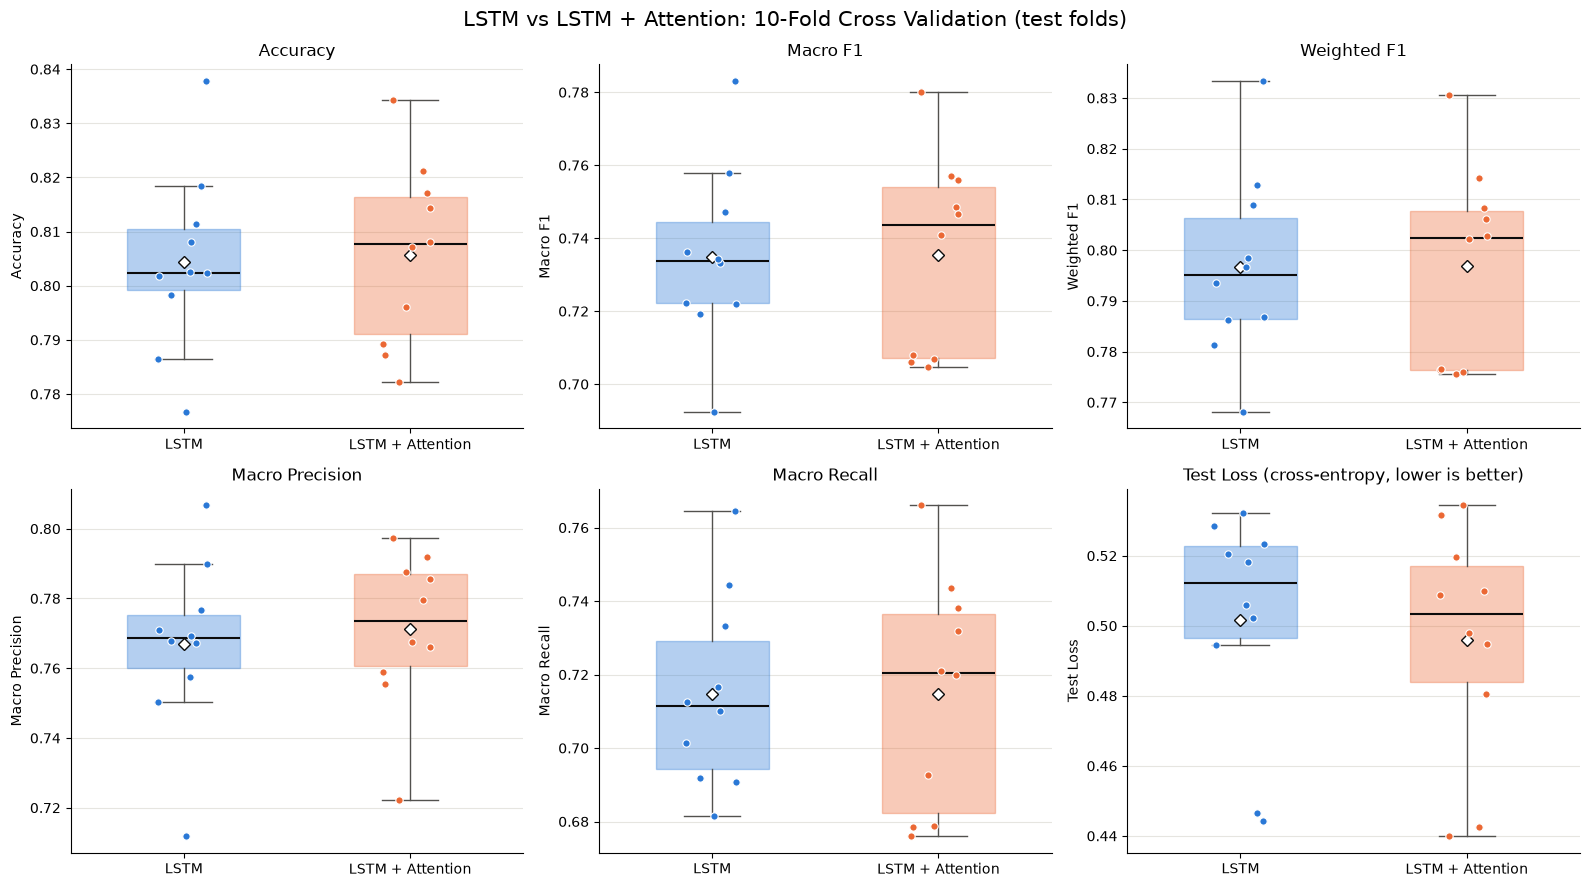

In [11]:
def compare_boxplot(ax, metric, title, ylabel=None):
    names = list(results)
    data = [results[n][metric].values for n in names]
    bp = ax.boxplot(
        data, widths=0.5, patch_artist=True, showmeans=True,
        medianprops=dict(color="#0b0b0b", linewidth=1.5),
        meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="#0b0b0b", markersize=6),
        whiskerprops=dict(color="#52514e"), capprops=dict(color="#52514e"),
        showfliers=False,   # every fold is already drawn as a dot below
    )
    ax.set_xticks(range(1, len(names) + 1), names)
    for patch, n in zip(bp["boxes"], names):
        patch.set_facecolor(MODEL_COLORS[n])
        patch.set_alpha(0.35)
        patch.set_edgecolor(MODEL_COLORS[n])
    rng = np.random.default_rng(0)
    for i, (n, d) in enumerate(zip(names, data), start=1):
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(d)), d, s=28, color=MODEL_COLORS[n],
                   edgecolor="white", linewidth=0.8, zorder=3)
    ax.set_title(title)
    ax.set_ylabel(ylabel or title)
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


perf_metrics = [
    ("accuracy", "Accuracy"),
    ("f1_macro", "Macro F1"),
    ("f1_weighted", "Weighted F1"),
    ("precision_macro", "Macro Precision"),
    ("recall_macro", "Macro Recall"),
    ("test_loss", "Test Loss (cross-entropy, lower is better)"),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (metric, title) in zip(axes.ravel(), perf_metrics):
    compare_boxplot(ax, metric, title, ylabel=title.split(" (")[0])
fig.suptitle(f"LSTM vs LSTM + Attention: {n_folds}-Fold Cross Validation (test folds)", fontsize=15)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "boxplot_overall_metrics.png"), dpi=150, bbox_inches="tight")
plt.show()

### Per-class F1 Score

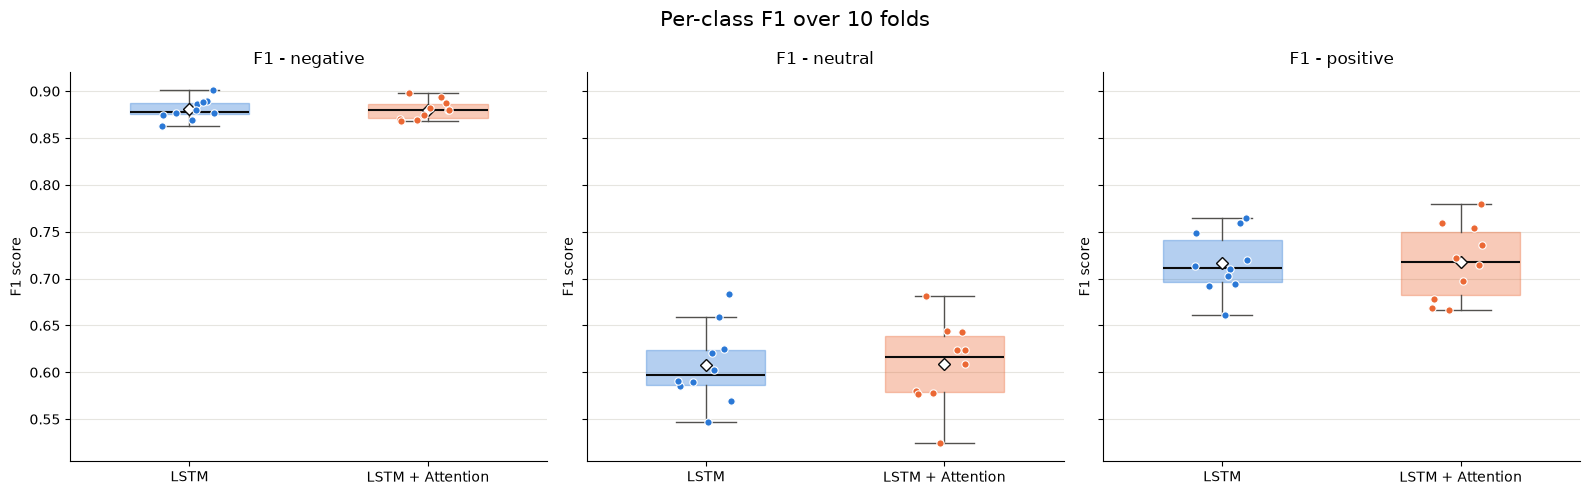

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, c in zip(axes, class_names):
    compare_boxplot(ax, f"f1_{c}", f"F1 - {c}", ylabel="F1 score")
fig.suptitle(f"Per-class F1 over {n_folds} folds", fontsize=15)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "boxplot_per_class_f1.png"), dpi=150, bbox_inches="tight")
plt.show()

### Training Cost

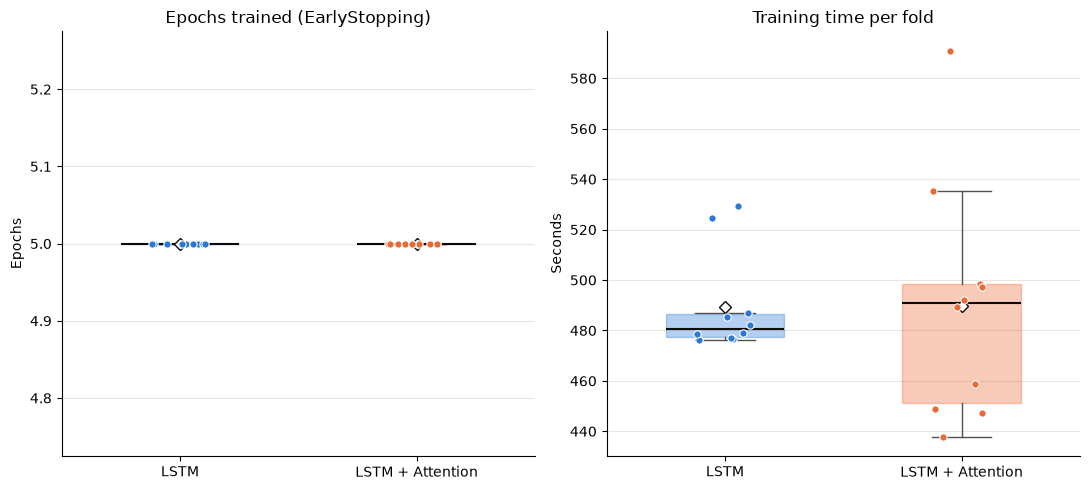

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
compare_boxplot(axes[0], "epochs_trained", "Epochs trained (EarlyStopping)", ylabel="Epochs")
compare_boxplot(axes[1], "train_time_s", "Training time per fold", ylabel="Seconds")
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "boxplot_training_cost.png"), dpi=150, bbox_inches="tight")
plt.show()

## Fold-by-Fold Comparison

Since both models are trained on the same folds, the scores are paired. The left plot joins the two scores of the same fold; the right plot shows the difference (Attention − LSTM) per fold. Bars above 0 mean attention was better on that fold.

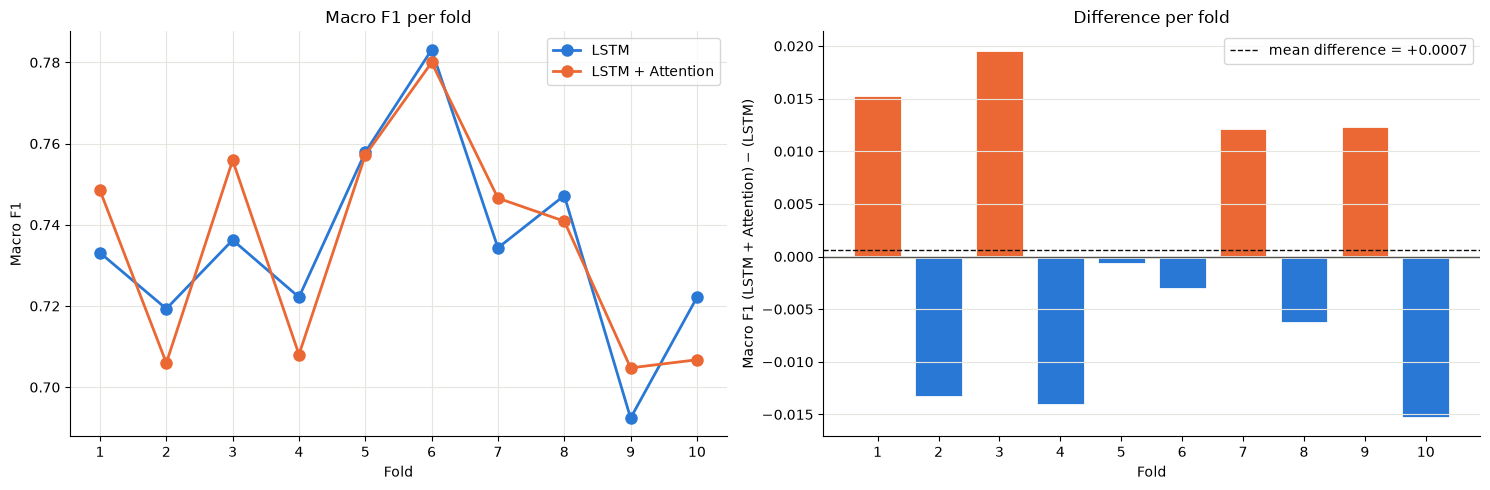

In [14]:
names = list(results)
a, b = names
fold_ids = results[a]["fold"].values

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for n in names:
    axes[0].plot(fold_ids, results[n]["f1_macro"], marker="o", linewidth=2, markersize=8,
                 color=MODEL_COLORS[n], label=n)
axes[0].set_xticks(fold_ids)
axes[0].set_xlabel("Fold"); axes[0].set_ylabel("Macro F1")
axes[0].set_title("Macro F1 per fold"); axes[0].legend()
axes[0].grid(color="#e6e5e0", linewidth=0.8)

diff = results[b]["f1_macro"].values - results[a]["f1_macro"].values
axes[1].bar(fold_ids, diff, color=[MODEL_COLORS[b] if d > 0 else MODEL_COLORS[a] for d in diff],
            edgecolor="white", linewidth=2)
axes[1].axhline(0, color="#52514e", linewidth=1)
axes[1].axhline(diff.mean(), color="#0b0b0b", linestyle="--", linewidth=1,
                label=f"mean difference = {diff.mean():+.4f}")
axes[1].set_xticks(fold_ids)
axes[1].set_xlabel("Fold"); axes[1].set_ylabel(f"Macro F1 ({b}) − ({a})")
axes[1].set_title("Difference per fold"); axes[1].legend()
axes[1].grid(axis="y", color="#e6e5e0", linewidth=0.8)
for ax in axes:
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "fold_by_fold_macro_f1.png"), dpi=150, bbox_inches="tight")
plt.show()

## Statistical Significance

Paired tests over the 10 folds (same folds for both models):

* **Paired t-test** – assumes the fold differences are roughly normal.
* **Wilcoxon signed-rank test** – non-parametric, does not assume normality.

p < 0.05 means the difference between the two models is unlikely to be due to chance in how the folds were trained.

In [15]:
rows = []
for metric, title in perf_metrics + [(f"f1_{c}", f"F1 - {c}") for c in class_names]:
    va, vb = results[a][metric].values, results[b][metric].values
    d = vb - va
    t_p = stats.ttest_rel(vb, va).pvalue
    try:
        w_p = stats.wilcoxon(vb, va).pvalue
    except ValueError:          # all differences are zero
        w_p = np.nan
    better = (d < 0).sum() if metric == "test_loss" else (d > 0).sum()
    rows.append({
        "metric": title.split(" (")[0],
        f"{a} mean": va.mean(),
        f"{b} mean": vb.mean(),
        "mean diff (Attn − LSTM)": d.mean(),
        "folds where Attention better": f"{better}/{n_folds}",
        "paired t-test p": t_p,
        "Wilcoxon p": w_p,
        "significant (p<0.05)": "yes" if t_p < 0.05 and (np.isnan(w_p) or w_p < 0.05) else "no",
    })
significance = pd.DataFrame(rows).set_index("metric")
significance.to_csv(os.path.join(output_dir, "cv_significance.csv"))
significance.round(4)

,LSTM mean,LSTM + Attention mean,mean diff (Attn − LSTM),folds where Attention better,paired t-test p,Wilcoxon p,significant (p<0.05)
metric,,,,,,,
Accuracy,0.8044,0.8057,0.0013,6/10,0.5656,0.6445,no
Macro F1,0.7348,0.7354,0.0007,4/10,0.8783,1.0000,no
Weighted F1,0.7966,0.7969,0.0002,5/10,0.9313,1.0000,no
Macro Precision,0.7668,0.7712,0.0044,7/10,0.1980,0.2324,no
Macro Recall,0.7147,0.7146,-0.0001,5/10,0.9902,0.9219,no
Test Loss,0.5017,0.4960,-0.0057,8/10,0.0474,0.0371,yes
F1 - negative,0.8806,0.8803,-0.0003,5/10,0.8373,0.8457,no
F1 - neutral,0.6073,0.6084,0.0011,4/10,0.8933,1.0000,no
F1 - positive,0.7164,0.7176,0.0012,6/10,0.8642,0.8457,no


## Pooled Confusion Matrices (out-of-fold predictions)

Every tweet is in the test fold exactly once, so joining the 10 test folds gives one prediction per tweet for the whole dataset.
Rows are normalised, so the diagonal is the recall of each class.

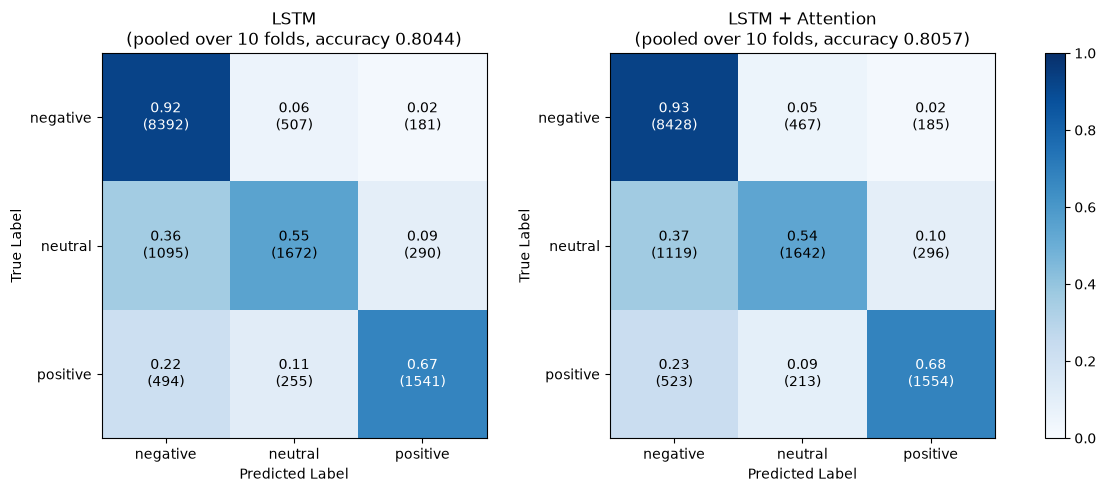

========== LSTM (pooled out-of-fold) ==========
              precision    recall  f1-score   support

    negative     0.8408    0.9242    0.8805      9080
     neutral     0.6869    0.5469    0.6090      3057
    positive     0.7659    0.6729    0.7164      2290

    accuracy                         0.8044     14427
   macro avg     0.7645    0.7147    0.7353     14427
weighted avg     0.7963    0.8044    0.7970     14427

========== LSTM + Attention (pooled out-of-fold) ==========
              precision    recall  f1-score   support

    negative     0.8369    0.9282    0.8802      9080
     neutral     0.7071    0.5371    0.6105      3057
    positive     0.7636    0.6786    0.7186      2290

    accuracy                         0.8057     14427
   macro avg     0.7692    0.7146    0.7364     14427
weighted avg     0.7978    0.8057    0.7974     14427



In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, n in zip(axes, names):
    pred = oof_probs[n].argmax(axis=1)
    cm = confusion_matrix(y_int, pred, labels=[0, 1, 2])
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{n}\n(pooled over {n_folds} folds, accuracy {accuracy_score(y_int, pred):.4f})")
    ax.set_xlabel("Predicted Label"); ax.set_ylabel("True Label")
    ax.set_xticks(range(3), class_names); ax.set_yticks(range(3), class_names)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm_norm[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center",
                    color="white" if cm_norm[i, j] > 0.6 else "black")
fig.colorbar(im, ax=axes, fraction=0.025)
fig.savefig(os.path.join(output_dir, "confusion_matrices_pooled.png"), dpi=150, bbox_inches="tight")
plt.show()

for n in names:
    print(f"========== {n} (pooled out-of-fold) ==========")
    print(classification_report(y_int, oof_probs[n].argmax(axis=1), target_names=class_names, digits=4))

## Validation Loss Curves for Every Fold

Thin lines are the 10 folds and the thick line is the mean over the folds that were still training at that epoch.

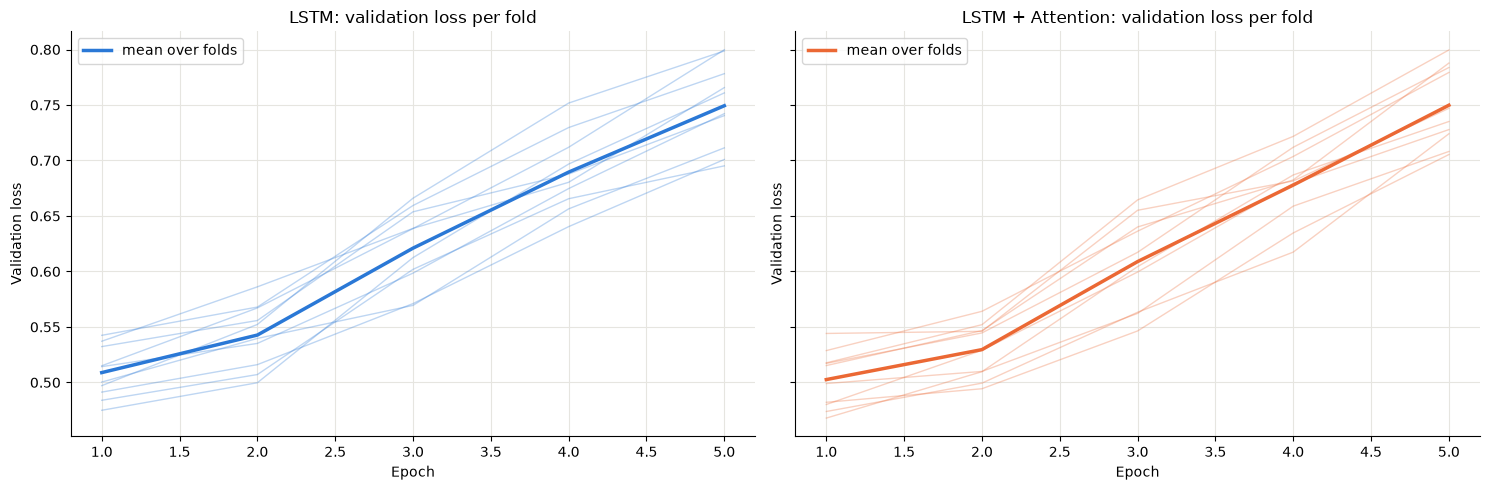

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, n in zip(axes, names):
    curves = [h["val_loss"] for h in histories[n]]
    for cv in curves:
        ax.plot(range(1, len(cv) + 1), cv, color=MODEL_COLORS[n], alpha=0.3, linewidth=1)
    longest = max(len(cv) for cv in curves)
    mean_curve = [np.mean([cv[e] for cv in curves if len(cv) > e]) for e in range(longest)]
    ax.plot(range(1, longest + 1), mean_curve, color=MODEL_COLORS[n], linewidth=2.5, label="mean over folds")
    ax.set_title(f"{n}: validation loss per fold")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Validation loss")
    ax.legend(); ax.grid(color="#e6e5e0", linewidth=0.8)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "val_loss_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

## Conclusion

In [18]:
r_a, r_b = results[a], results[b]
print(f"{'Metric':<18}{a:>22}{b:>22}")
for metric, title in perf_metrics:
    print(f"{title.split(' (')[0]:<18}"
          f"{r_a[metric].mean():>14.4f} ± {r_a[metric].std():.4f}"
          f"{r_b[metric].mean():>14.4f} ± {r_b[metric].std():.4f}")
print(f"{'Parameters':<18}{int(r_a['n_params'][0]):>22,}{int(r_b['n_params'][0]):>22,}")
print(f"{'Train time / fold':<18}{r_a['train_time_s'].mean():>21.0f}s{r_b['train_time_s'].mean():>21.0f}s")
print()

d = r_b["f1_macro"].mean() - r_a["f1_macro"].mean()
sig = significance.loc["Macro F1", "significant (p<0.05)"] == "yes"
winner = b if d > 0 else a
if sig:
    print(f"{winner} is significantly better on macro F1 ({d:+.4f}, p < 0.05 on both paired tests).")
else:
    print(f"Mean macro F1 difference is {d:+.4f} ({winner} slightly ahead), but it is NOT statistically "
          f"significant over the {n_folds} folds: the two models perform about the same on this dataset.")

Metric                              LSTM      LSTM + Attention
Accuracy                  0.8044 ± 0.0167        0.8057 ± 0.0167
Macro F1                  0.7348 ± 0.0245        0.7354 ± 0.0270
Weighted F1               0.7966 ± 0.0184        0.7969 ± 0.0195
Macro Precision           0.7668 ± 0.0250        0.7712 ± 0.0223
Macro Recall              0.7147 ± 0.0261        0.7146 ± 0.0316
Test Loss                 0.5017 ± 0.0319        0.4960 ± 0.0331
Parameters                     1,379,203             1,387,523
Train time / fold                   490s                  490s

Mean macro F1 difference is +0.0007 (LSTM + Attention slightly ahead), but it is NOT statistically significant over the 10 folds: the two models perform about the same on this dataset.
